In [1]:
# We need it in all codes
import numpy as np 
import math

# We again measure computational time and try to use sparse matrices
import scipy.sparse
from scipy.sparse import csr_matrix
from timeit import default_timer as timer

# We manipulate again a picture
from PIL import Image
import matplotlib.pyplot as plt


# See functions here
# https://numpy.org/doc/stable/reference/generated/numpy.exp.html
# https://numpy.org/doc/stable/reference/routines.array-manipulation.html
#

# basic vector and matrix operations
# general principle: we do not have to write functions for everything
# moreover, built-in vectorized operations are rather fast

(a) Generate ten random points with integer coordinates between 0 and 20 in the plane. Construct
a matrix A ∈ R10×10 such that A[j, k] is the l1-distance of the random points Pj and Pk.

In [40]:
x = np.random.randint(0,20,10)
y = np.random.randint(0,20,10)

#building my grid
Points = np.stack ((x, y), axis =1)
#A is symmetric, so building only the upper triangular part is enough
#We also know the distance of a point with itself is zero. Moreover,
A = np.zeros ((10,10))
for j in np.arange(10):
    pj = Points[j,:]
    pk = Points[j+1:,:]
    A [j,j+1:] = np.linalg.norm (pj - pk, 1, axis =1)

A = A + A.T
print(A)

[[ 0.  9. 11.  9. 18. 20. 28. 26. 15. 13.]
 [ 9.  0.  8.  8. 17. 11. 19. 17.  8.  4.]
 [11.  8.  0. 16. 25. 17. 17. 15.  4.  8.]
 [ 9.  8. 16.  0.  9. 13. 21. 19. 16.  8.]
 [18. 17. 25.  9.  0.  8. 14. 20. 25. 17.]
 [20. 11. 17. 13.  8.  0.  8. 12. 17.  9.]
 [28. 19. 17. 21. 14.  8.  0. 12. 17. 15.]
 [26. 17. 15. 19. 20. 12. 12.  0. 11. 13.]
 [15.  8.  4. 16. 25. 17. 17. 11.  0.  8.]
 [13.  4.  8.  8. 17.  9. 15. 13.  8.  0.]]


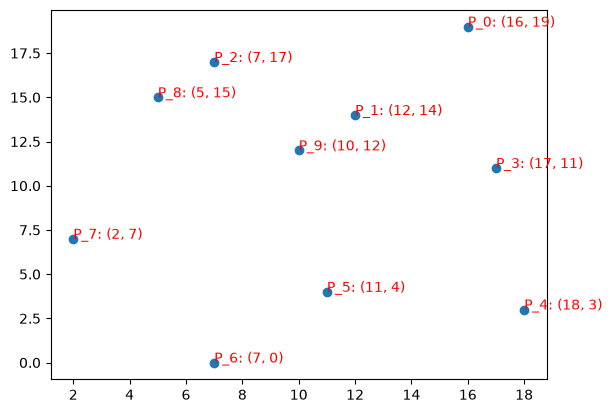

In [41]:
plt.scatter(x,y)
for i in np.arange(10):
    plt.text(x[i], y[i], f"P_{i}: ({x[i]}, {y[i]})", color = 'red', size =10)

plt.show()

In [53]:
r = 5
Connectivity_m = (A <= r).astype(int)
np.fill_diagonal(Connectivity_m,0)
print(Connectivity_m)
#Checking how many connections each Pi has:
conn = np.sum(Connectivity_m@Connectivity_m, axis = 1)
conn

[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0 0 0]]


array([0, 1, 1, 0, 0, 0, 0, 0, 1, 1])

b) Check that the distances in the above matrix really satisfy the triangle inequality. (Of course;
we know that but this serves as a test case to verify that a given symmetric non-negative matrix
can really be recognized as a distance-matrix.)

In [4]:
checker = np.zeros((10,10))
for  j in np.arange(10):
    for k in np.arange(j+1,10):
        for i in np.arange(10):
            if A[j,k] <= A[j,i] + A[i,k]:
                checker[j,k] = True 

#This seems to be not efficient. How can we do this comparison without any for loop?


In [5]:
#Without loops, using 3d arrays and broadcasting
# Copies A in the 3rd axis
A_ij = A[:, :, None]
# Copies A in the 2nd axis
A_ik = A[:, None, :]
# Copies A in the first axis
A_jk = A[None, :,:] 
# e.g [i,j,k] = [1, 2,3] will compare A[1,3] with A[1,2] and A[2,3] 
checker = (A_ik <= A_ij + A_jk)

if np.all(checker):
    print(f"The matrix satisfies the triangle inequality")

The matrix satisfies the triangle inequality


(c)Try to save some computational time in the SVD reduction of pictures. First perform a full
SVD decomposition and then cut by the first 25 singular values. Then look after and apply
a truncated SVD decomposition with 25 singular values and restore the original picture. Are
they of the same quality? Compare computational times.

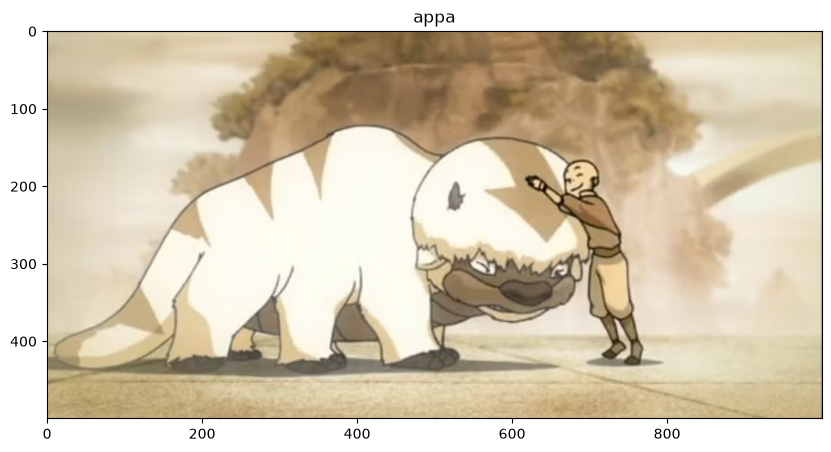

In [ ]:
#Get the image:
image = np.array(Image.open("/Users/thestral21/PhD/Seminar linear algebra 2026/AI_linalg_materials/appa.jpg")) 

fig = plt.figure(figsize=(10, 10))
imgplot = plt.imshow(image)
plt.title("appa")
plt.show()
    

In [7]:
#We perform SVD decomposition for each color:
red_comp = image [:, :, 0]
green_comp = image [:,:,1]
blue_comp = image [:,:,2]

#The data in integer form, let's change it to float for better manipulation:
red_comp = red_comp.astype('float64')
green_comp = green_comp.astype('float64')
blue_comp = blue_comp.astype('float64')

print(f"The shape of this image is {np.shape(image)}")
print(f"This means that each component has {np.min(np.shape(image[:,:,0]))} singular values")

The shape of this image is (500, 1000, 3)
This means that each component has 500 singular values


In [14]:
#Full matrix decomposition A = U ∑ V^T, A shape = (n,k)
#This function returns U and V (if compute_uv =TRUE) and the singular values in an array of size r = min(n,k)
#Hermitian false since we know A is not symmetric.
start = timer()

#SVD full process
U_red, s_red, Vt_red = np.linalg.svd(red_comp, full_matrices=True, compute_uv=True, hermitian=False) 
U_green, s_green, Vt_green = np.linalg.svd(green_comp, full_matrices=True, compute_uv=True, hermitian=False) 
U_blue, s_blue, Vt_blue= np.linalg.svd(blue_comp, full_matrices=True, compute_uv=True, hermitian=False) 

#Compressing A with only the first k singular values:
k = 150
red_comp_c = U_red[:, : k ] @ np.diag(s_red[:k]) @ Vt_red [:k, :] 
green_comp_c = U_green[:, : k ] @ np.diag(s_green[:k]) @ Vt_green [:k, :] 
blue_comp_c = U_blue[:, : k ] @ np.diag(s_blue[:k]) @ Vt_blue [:k, :] 

#Restoring the image:
compressed_shape =   (red_comp_c.shape[0], red_comp_c.shape[1],3)
appa_compr = np.zeros( compressed_shape)

appa_compr [:,:, 0] = red_comp_c
appa_compr [:,:, 1] = green_comp_c
appa_compr [:,:, 2] = blue_comp_c

appa_compr = appa_compr.astype( int)
end = timer()

print(f"This compressing took {end-start} seconds")

This compressing took 0.12324033400363987 seconds


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-7..260].


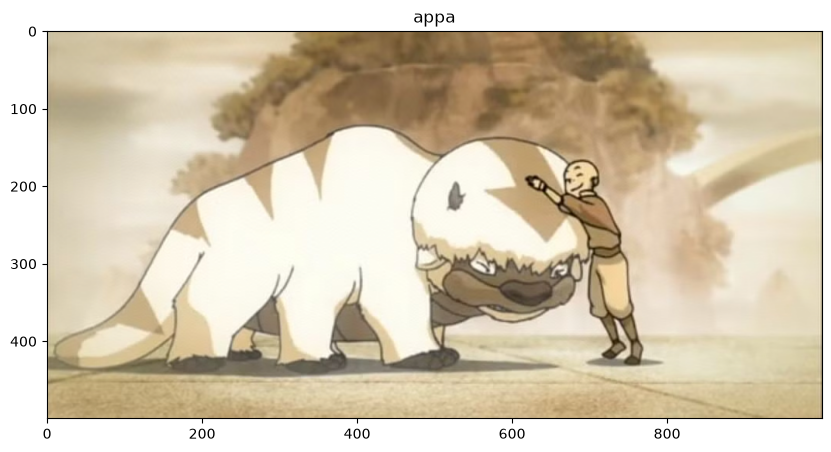

In [15]:
fig = plt.figure(figsize=(10, 10))
imgplot = plt.imshow(appa_compr)
plt.title("appa")
plt.show()

In [16]:
#Now performing the same test but with a reduced SVD:

start = timer ()

#SVD reduced process
U_red, s_red, Vt_red = np.linalg.svd(red_comp, full_matrices=False, compute_uv=True, hermitian=False) 
U_green, s_green, Vt_green = np.linalg.svd(green_comp, full_matrices=False, compute_uv=True, hermitian=False) 
U_blue, s_blue, Vt_blue= np.linalg.svd(blue_comp, full_matrices=False, compute_uv=True, hermitian=False) 

#Compressing A with only the first 25 singular values:
red_comp_c = U_red[:, : k ] @ np.diag(s_red[:k]) @ Vt_red [:k, :] 
green_comp_c = U_green[:, : k ] @ np.diag(s_green[:k]) @ Vt_green [:k, :] 
blue_comp_c = U_blue[:, : k ] @ np.diag(s_blue[:k]) @ Vt_blue [:k, :]

#Restoring the image:
compressed_shape =   (red_comp_c.shape[0], red_comp_c.shape[1],3)
appa_compr = np.zeros( compressed_shape)

appa_compr [:,:, 0] = red_comp_c
appa_compr [:,:, 1] = green_comp_c
appa_compr [:,:, 2] = blue_comp_c

appa_compr = appa_compr.astype( int)
end = timer()

print(f"This compressing took {end-start} seconds")

This compressing took 0.10344316699774936 seconds


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-7..260].


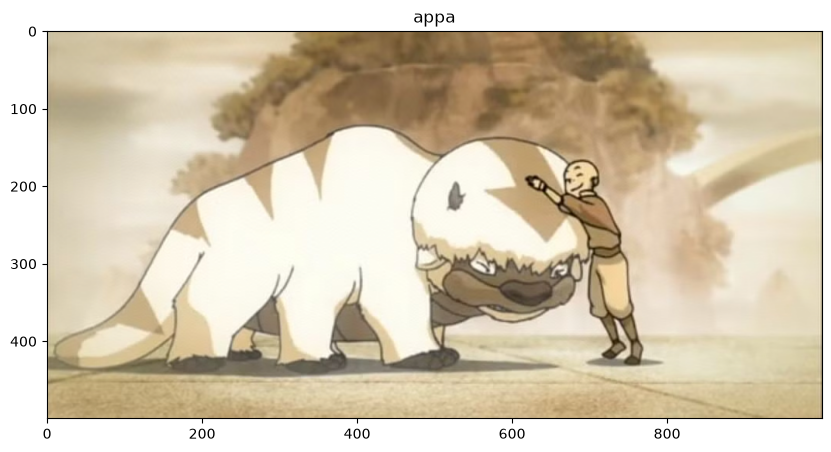

In [17]:
fig = plt.figure(figsize=(10, 10))
imgplot = plt.imshow(appa_compr)
plt.title("appa")
plt.show()